# Lab 12.2: Dissect a Small Network, then Test a Concept

Chapter 12, Concepts Inside Networks. Run-only notebook: run the cells in order and read the output. Nothing needs to be edited.

You will (1) train a small convolutional network to say which of three textures (stripes, dots, checkerboard) appear in an image, (2) dissect its second layer: for every unit, find the concept whose pixels it lights up best (intersection over union, IoU, as in Bau et al., 2017), (3) compare the best single unit with a learned linear combination of all units (as in Fong and Vedaldi, 2018), and (4) run TCAV (Kim et al., 2018) for two concepts, with the random-concept test that tells a real result from noise.

In [1]:
import numpy as np, torch, torch.nn as nn
from scipy import stats
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt
torch.manual_seed(0); torch.set_num_threads(4)
rng = np.random.default_rng(0)

## 1. Synthetic images with known concept masks

Every image is gray noise with up to three rectangular patches, each of one texture. Because we drew the patches ourselves, we know exactly which pixels belong to which concept: the ground truth that network dissection needs.

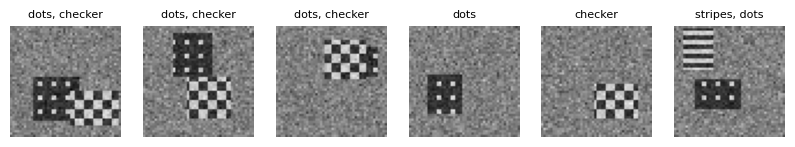

training images: 3000  test images: 400


In [2]:
def texture_images(n, rng, size=48):
    yy, xx = np.mgrid[:size, :size]
    pats = [((yy // 2) % 2).astype(float),                              # stripes
            (((yy % 6) < 2) & ((xx % 6) < 2)).astype(float),             # dots
            (((yy // 4) + (xx // 4)) % 2).astype(float)]                 # checkerboard
    X = rng.normal(0.5, 0.08, (n, size, size)); M = np.zeros((n, 3, size, size), bool)
    for i in range(n):
        for c in range(3):
            if rng.random() < 0.5:
                h, w = rng.integers(12, 22, 2); y0, x0 = rng.integers(0, size - h), rng.integers(0, size - w)
                X[i, y0:y0+h, x0:x0+w] = 0.2 + 0.6 * pats[c][y0:y0+h, x0:x0+w] + rng.normal(0, 0.05, (h, w))
                M[i, c, y0:y0+h, x0:x0+w] = True
    for i in range(n):
        for c in range(3):
            for c2 in range(c + 1, 3):
                M[i, c] &= ~M[i, c2]                                     # later patches cover earlier ones
    return X.astype(np.float32), M, M.reshape(n, 3, -1).any(-1).astype(np.float32)

names = ["stripes", "dots", "checker"]
Xtr, _, Ytr = texture_images(3000, rng); Xte, Mte, Yte = texture_images(400, rng)
fig, axes = plt.subplots(1, 6, figsize=(10, 2))
for i, ax in enumerate(axes):
    ax.imshow(Xte[i], cmap="gray", vmin=0, vmax=1); ax.axis("off")
    ax.set_title(", ".join(n for n, y in zip(names, Yte[i]) if y) or "none", fontsize=8)
plt.show()
print("training images:", len(Xtr), " test images:", len(Xte))

## 2. Train the network (about 20 seconds)

In [3]:
net = nn.Sequential(nn.Conv2d(1, 8, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(),            # layer we dissect: 16 units
                    nn.MaxPool2d(2), nn.Conv2d(16, 16, 3, padding=1), nn.ReLU(),
                    nn.AdaptiveMaxPool2d(1), nn.Flatten(), nn.Linear(16, 3))
opt = torch.optim.Adam(net.parameters(), 3e-3); xt, yt = torch.tensor(Xtr[:, None]), torch.tensor(Ytr)
for ep in range(8):
    perm = torch.randperm(len(xt))
    for b in range(0, len(xt), 64):
        j = perm[b:b+64]; opt.zero_grad()
        nn.functional.binary_cross_entropy_with_logits(net(xt[j]), yt[j]).backward(); opt.step()
with torch.no_grad():
    acc = ((net(torch.tensor(Xte[:, None])) > 0).float().numpy() == Yte).mean()
print("test accuracy per label: %.3f" % acc)

test accuracy per label: 0.992


**Checkpoint 1.** The accuracy per label should be about 0.99.

## 3. Network dissection

For each unit we take its activation map, upsample it to the image size, keep the pixels where the unit is in its top 5 percent of activations over the whole test set, and compute the IoU of that region with each concept's mask. Bau et al. (2017) used a top quantile of 0.5 percent on their large Broden dataset and called a unit a detector when IoU exceeded 0.04; our concepts cover more of each image, so we use 5 percent.

In [4]:
with torch.no_grad():
    A = net[:5](torch.tensor(Xte[:, None])).numpy()            # (images, 16 units, 24, 24)
A = A.repeat(2, axis=2).repeat(2, axis=3)                      # upsample to 48 x 48
U = A.transpose(0, 2, 3, 1).reshape(-1, 16)                    # one row per pixel
Mf = Mte.transpose(0, 2, 3, 1).reshape(-1, 3)

def ious(U, q=0.05):
    on = U > np.quantile(U, 1 - q, axis=0)
    inter = on.T.astype(np.float32) @ Mf.astype(np.float32)
    union = on.sum(0)[:, None] + Mf.sum(0)[None, :] - inter
    return inter / union                                         # units x concepts

I = ious(U)
for k in np.argsort(-I.max(1)):
    best = I[k].argmax(); second = np.sort(I[k])[-2]
    print("unit %2d  best: %-8s IoU %.2f   second-best IoU %.2f" % (k, names[best], I[k, best], second))
print("units above IoU 0.04:", (I.max(1) > 0.04).sum(), "of 16")

unit 15  best: dots     IoU 0.33   second-best IoU 0.25
unit  9  best: checker  IoU 0.31   second-best IoU 0.19
unit 11  best: checker  IoU 0.30   second-best IoU 0.23
unit 10  best: stripes  IoU 0.28   second-best IoU 0.17
unit  4  best: stripes  IoU 0.28   second-best IoU 0.01
unit  3  best: stripes  IoU 0.28   second-best IoU 0.19
unit  5  best: stripes  IoU 0.28   second-best IoU 0.13
unit  6  best: stripes  IoU 0.28   second-best IoU 0.08
unit  1  best: stripes  IoU 0.26   second-best IoU 0.25
unit  0  best: stripes  IoU 0.24   second-best IoU 0.23
unit 14  best: checker  IoU 0.18   second-best IoU 0.16
unit  7  best: checker  IoU 0.18   second-best IoU 0.08
unit 13  best: stripes  IoU 0.12   second-best IoU 0.00
unit  2  best: dots     IoU 0.09   second-best IoU 0.01
unit  8  best: stripes  IoU 0.00   second-best IoU 0.00
unit 12  best: stripes  IoU 0.00   second-best IoU 0.00
units above IoU 0.04: 14 of 16


**Checkpoint 2.** About 14 of 16 units pass the 0.04 threshold, but the best IoU of any unit is only about 0.3, and most units also overlap a second concept. A label such as "stripe detector" is a summary of a weak, mixed match.

## 4. One unit, or a direction?

Now we let a logistic regression combine all 16 units to segment each concept, and compare its IoU with the best single unit.

In [5]:
sub = np.random.default_rng(2).choice(len(U), 60000, replace=False)
for c in range(3):
    clf = LogisticRegression(max_iter=500).fit(U[sub], Mf[sub, c])
    s = U @ clf.coef_[0]; on = s > np.quantile(s, 1 - Mf[:, c].mean())
    comb = (on & Mf[:, c]).sum() / (on | Mf[:, c]).sum()
    print("%-8s best single unit IoU %.2f   linear combination IoU %.2f" % (names[c], I[:, c].max(), comb))

stripes  best single unit IoU 0.28   linear combination IoU 0.82
dots     best single unit IoU 0.33   linear combination IoU 0.78


checker  best single unit IoU 0.31   linear combination IoU 0.81


**Checkpoint 3.** A combination of units reaches an IoU near 0.8 for every concept, against about 0.3 for the best single unit. The concept lives in a direction of the layer, not in one unit.

## 5. TCAV with a random-concept test

Question: how sensitive is the "stripes" output to the concept *stripes*, and to the concept *dots*? We build concept example sets (images made of one texture only), random example sets (plain noise images), learn a concept activation vector (CAV) at the dissected layer, and count the share of stripe-containing test images whose stripes logit rises when the activations move along the CAV. Then we repeat with 20 random sets, and compare with random-versus-random CAVs.

In [6]:
def pure(c, n, rng):
    X, _, _ = texture_images(n, rng); out = []
    yy, xx = np.mgrid[:48, :48]
    pats = [((yy // 2) % 2), (((yy % 6) < 2) & ((xx % 6) < 2)), (((yy // 4) + (xx // 4)) % 2)]
    for i in range(n):
        h, w = rng.integers(16, 30, 2); y0, x0 = rng.integers(0, 48 - h), rng.integers(0, 48 - w)
        img = rng.normal(0.5, 0.08, (48, 48)); img[y0:y0+h, x0:x0+w] = 0.2 + 0.6 * pats[c][y0:y0+h, x0:x0+w]
        out.append(img)
    return np.array(out, dtype=np.float32)

rc = np.random.default_rng(5)
concepts = {"stripes": pure(0, 50, rc), "dots": pure(1, 50, rc)}
randoms = [rc.normal(0.5, 0.08, (50, 48, 48)).astype(np.float32) for _ in range(21)]
cls = Xte[Yte[:, 0] == 1]                                       # test images that contain stripes

def acts(X):
    with torch.no_grad(): return net[:5](torch.tensor(X[:, None])).reshape(len(X), -1).numpy()
a = net[:5](torch.tensor(cls[:, None])).detach().requires_grad_(True)
net[5:](a)[:, 0].sum().backward()                               # gradient of the stripes logit
g = a.grad.reshape(len(cls), -1).numpy()

def cav(P, N):
    Z = np.r_[P, N]; y = np.r_[np.ones(len(P)), np.zeros(len(N))]
    v = LogisticRegression(max_iter=2000).fit(Z, y).coef_[0]; return v / np.linalg.norm(v)

R = [acts(r) for r in randoms]
null = [np.mean(g @ cav(R[i], R[i + 1]) > 0) for i in range(20)]
print("random vs random: %.2f +/- %.2f" % (np.mean(null), np.std(null)))
for name, Xc in concepts.items():
    Ac = acts(Xc); S = [np.mean(g @ cav(Ac, R[i]) > 0) for i in range(20)]
    print("%-8s TCAV %.2f +/- %.2f   t-test against random: p = %.1e" % (name, np.mean(S), np.std(S), stats.ttest_ind(S, null).pvalue))

random vs random: 0.52 +/- 0.13


stripes  TCAV 1.00 +/- 0.00   t-test against random: p = 6.7e-19


dots     TCAV 0.13 +/- 0.02   t-test against random: p = 1.9e-15


**Checkpoint 4.** Write down the TCAV scores for stripes and dots and the spread of the random-versus-random scores. Note how wide the random spread is: a single CAV, trained once against one random set, can give almost any score. That is why Kim et al. (2018) repeat the test against many random sets and keep only concepts that pass a statistical test.

## Questions

1. Which units would you call "stripe detectors"? Would you still use that word after looking at their second-best IoU?
2. Why does a linear combination segment each concept so much better than any single unit? What does this mean for methods that label units one by one?
3. Is the dots concept's TCAV score for the stripes output a finding about the model, or about the concept sets you chose? Design one change to the concept or random sets that would help you tell.